# Mission 03 - Multi-Head Attention, RoPE & GQA KV-Cache
Squadron Fei-Fei (Group 13), Conversational AI, BTU WS 2026/27.

This notebook integrates the four station deliverables. Each part lives in its own script; the notebook imports and runs them so results here and in the terminal are identical.

In [1]:
import importlib.util, json, platform, torch
from pathlib import Path
from IPython.display import Image, display

def load(name, filename):
    spec = importlib.util.spec_from_file_location(name, Path(filename))
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

mha = load('mha_core', '01_MultiHead_Attention_Core.py')
rope = load('rope_engine', '02_RoPE_Positional_Engine.py')
gqa = load('gqa_bench', '03_GQA_and_KVCache_Benchmark.py')
audit = load('memory_audit', '04_memory_audit_simulation.py')
print('torch', torch.__version__, '|', platform.platform())

torch 2.2.2 | macOS-26.4.1-x86_64-i386-64bit


## Part 1 - Systems Architect: scaled dot-product & multi-head self-attention
Attention(Q, K, V) = softmax(QK^T / sqrt(d_k)) V, built from scratch with W_Q, W_K, W_V, W_O, head splitting `(b, n, h, d) -> (b, h, n, d)` and a -inf causal mask above the diagonal.

In [2]:
mha.main()

=== Part 1: Variance preservation ===
  d_k |  Var(q.k) | Var(q.k/sqrt(d_k)) | result
   16 |    16.311 |             1.0195 | PASS
   64 |    64.176 |             1.0027 | PASS
  128 |   128.128 |             1.0010 | PASS
Mean max softmax weight, d_k=64: unscaled 0.771, scaled 0.069

=== Part 1: Multi-head forward pass ===
Input (2, 16, 256) -> output (2, 16, 256), attention (2, 4, 16, 16)
Max attention weight on future tokens: 0.0e+00 (causal mask)
Rows sum to 1: True
Max |ours - torch SDPA| = 5.96e-08
[PASS] Multi-head attention core verified.


Try other attention parameters: the causal mask must keep every future weight at exactly 0.

In [3]:
for d_model, heads, n in [(64, 2, 8), (128, 8, 32), (512, 16, 64)]:
    layer = mha.MultiHeadSelfAttention(d_model, heads).eval()
    out, w = layer(torch.randn(1, n, d_model))
    print(f'd_model={d_model:<4} heads={heads:<3} n={n:<3} out={tuple(out.shape)} '
          f'future weight max={w.triu(diagonal=1).max().item():.1f}')

d_model=64   heads=2   n=8   out=(1, 8, 64) future weight max=0.0
d_model=128  heads=8   n=32  out=(1, 32, 128) future weight max=0.0
d_model=512  heads=16  n=64  out=(1, 64, 512) future weight max=0.0


## Part 2 - Protocol Officer: Rotary Position Embeddings
theta_i = 10000^(-2(i-1)/d); each pair (x_2i, x_2i+1) is rotated by m * theta_i using complex multiplication. Because R_m^T R_n = R_(n-m), the score <RoPE(q,m), RoPE(k,n)> depends only on n - m.

=== Part 2: RoPE relative shift invariance ===
Example: <RoPE(q,763),RoPE(k,2235)> = 5.775354; shifted by delta=379: 5.775355
200 random (q, k, m, n, delta) trials, max relative error 2.38e-06
Rotation preserves vector norms: True

=== Part 2: Distance decay (RoPE self-similarity, head_dim=128) ===


d=0: +1.000 | d=1: +0.970 | d=4: +0.759 | d=16: +0.620 | d=64: +0.477 | d=256: +0.321 | d=1024: +0.204 | d=2048: +0.119
ALiBi slopes for 8 heads: ['1/2', '1/4', '1/8', '1/16', '1/32', '1/64', '1/128', '1/256']
Plot saved: evidence/rope_vs_alibi.png
[PASS] RoPE engine verified.


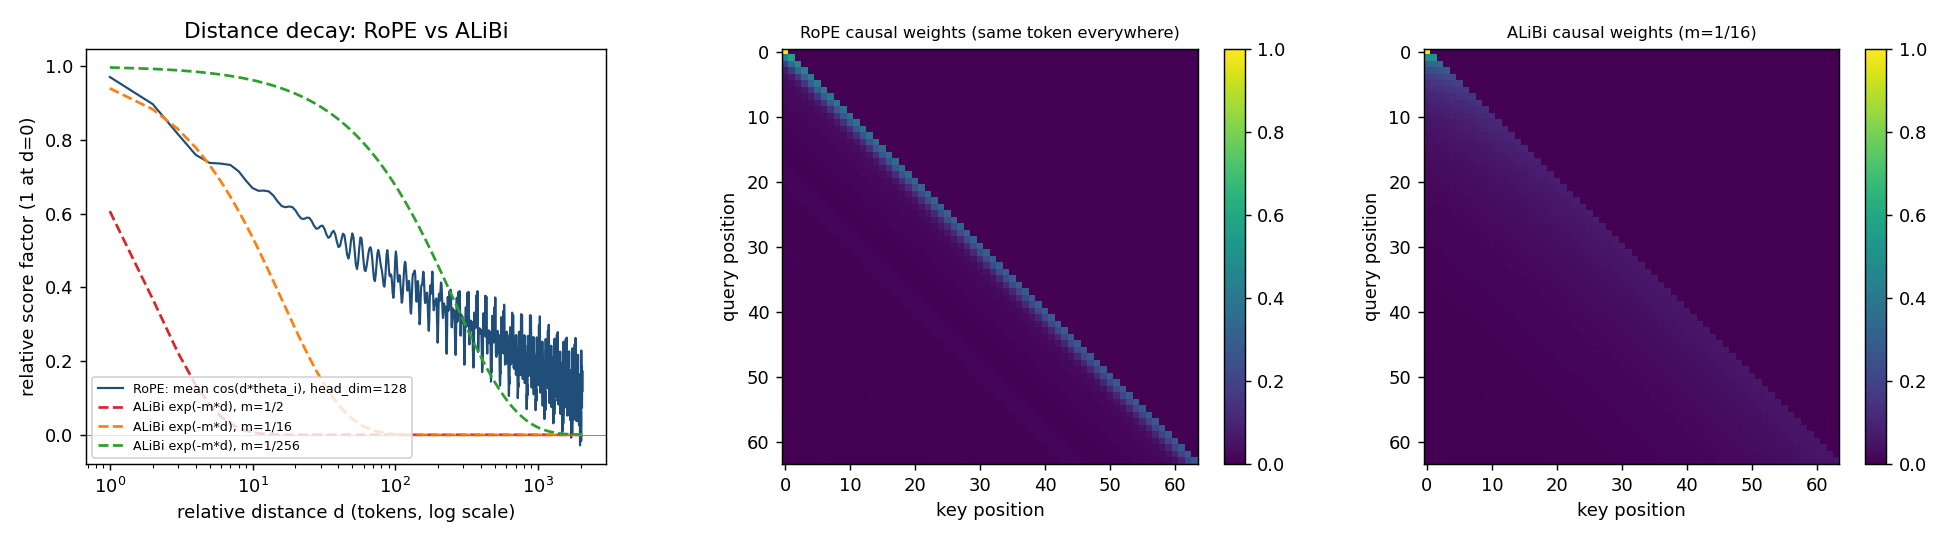

In [4]:
rope.main()
display(Image('evidence/rope_vs_alibi.png'))

## Part 3 - Data & Payload Specialist: GQA and KV-cache
Correctness checks run live. The full N = 1024 ... 32768 benchmark takes a few minutes on CPU, so the notebook shows the recorded run from `evidence/benchmark.json` (produced by `python 03_GQA_and_KVCache_Benchmark.py`).

In [5]:
torch.manual_seed(0)
layer = gqa.GQAAttention(d_model=256, num_q_heads=8, num_kv_heads=2).eval()
x = torch.randn(2, 24, 256)
with torch.no_grad():
    full = layer(x)
    cache = layer.new_cache(2, 24)
    parts = [layer(x[:, :16], cache)] + [layer(x[:, t:t + 1], cache) for t in range(16, 24)]
print('cached decode vs full forward, max diff:', (torch.cat(parts, 1) - full).abs().max().item())
print('grouped GQA vs repeat_interleave reference:', (full - gqa.reference_gqa(layer, x)).abs().max().item())

cached decode vs full forward, max diff: 1.6391277313232422e-07
grouped GQA vs repeat_interleave reference: 1.6391277313232422e-07


In [6]:
result = json.loads(Path('evidence/benchmark.json').read_text())
gqa.print_benchmark(result)
print('\nRecorded on:', result['hardware'])

     N | Variant         | KV-cache MB | GB/s @50 tok/s | 1-layer MB | ms/token
----------------------------------------------------------------------------------
  1024 | MHA 32:32       |       512.0 |          26.84 |       32.0 |    17.81
  1024 | GQA 32:8 (4:1)  |       128.0 |           6.71 |        8.0 |     8.98
  1024 | MQA 32:1        |        16.0 |           0.84 |        1.0 |     8.79
  4096 | MHA 32:32       |      2048.0 |         107.37 |      128.0 |    26.28
  4096 | GQA 32:8 (4:1)  |       512.0 |          26.84 |       32.0 |    10.34
  4096 | MQA 32:1        |        64.0 |           3.36 |        4.0 |     8.77
 16384 | MHA 32:32       |      8192.0 |         429.50 |      512.0 |    45.58
 16384 | GQA 32:8 (4:1)  |      2048.0 |         107.37 |      128.0 |    14.82
 16384 | MQA 32:1        |       256.0 |          13.42 |       16.0 |     9.68
 32768 | MHA 32:32       |     16384.0 |         858.99 |     1024.0 |    87.54
 32768 | GQA 32:8 (4:1)  |      4096.

## Part 4 - Security Sentinel: FlashAttention IO and KV-cache DoS
Full derivation and mitigation analysis: `04_Memory_Hierarchy_and_Safety_Audit.md`.

In [7]:
audit.main()

=== Part 4: HBM element accesses per head (d=128, SRAM 192 KiB) ===
     N | Standard (M) | Flash (M) | ratio | S matrix MiB | Flash m,l KiB
  1024 |          4.7 |       2.6 |  1.80 |            2 |             8
  4096 |         69.2 |      35.7 |  1.94 |           32 |            32
 16384 |       1082.1 |     545.3 |  1.98 |          512 |           128
 65536 |      17213.4 |    8623.5 |  2.00 |         8192 |           512

=== Part 4: KV-cache budget: 80 GiB x 0.9 - 15.0 GiB weights = 57.0 GiB ===
MHA 32:32         512.0 KiB/token |  32.00 GiB per 65,536-token session |   1 sessions before OOM
GQA 32:8          128.0 KiB/token |   8.00 GiB per 65,536-token session |   7 sessions before OOM
MQA 32:1           16.0 KiB/token |   1.00 GiB per 65,536-token session |  57 sessions before OOM
MLA d_c=512+64     36.0 KiB/token |   2.25 GiB per 65,536-token session |  25 sessions before OOM

=== Part 4: DoS simulation (160 cadet chats, 1 rogue 65k session per 4 chats) ===
Policy       | 

## Unified test suite

In [8]:
import subprocess, sys
r = subprocess.run([sys.executable, '-m', 'unittest', '-v', 'test_mission03.py'], capture_output=True, text=True)
print(r.stderr)

test_future_tokens_do_not_change_past_outputs (test_mission03.Part1AttentionTests) ... ok
test_matches_torch_reference (test_mission03.Part1AttentionTests) ... ok
test_padding_mask (test_mission03.Part1AttentionTests) ... ok
test_shapes_and_causal_mask (test_mission03.Part1AttentionTests) ... ok
test_variance_preservation (test_mission03.Part1AttentionTests) ... ok
test_frequencies (test_mission03.Part2RopeTests) ... ok
test_long_range_decay (test_mission03.Part2RopeTests) ... ok
test_matches_explicit_2d_rotation (test_mission03.Part2RopeTests) ... ok
test_norm_preserved_and_position_zero_is_identity (test_mission03.Part2RopeTests) ... ok
test_relative_invariance (test_mission03.Part2RopeTests) ... ok
test_score_depends_only_on_offset (test_mission03.Part2RopeTests) ... ok
test_cache_memory_and_overflow (test_mission03.Part3GqaCacheTests) ... ok
test_cached_decoding_equals_full_forward (test_mission03.Part3GqaCacheTests) ... ok
test_kv_cache_sizes (test_mission03.Part3GqaCacheTests) ..

## Squadron sign-off
Each officer ticks their own box after reviewing their part.

- [ ] Systems Architect: Bilal Younus
- [ ] Communications & Protocol Officer: Danish Hafeez
- [ ] Data & Payload Specialist: Anas Arshad
- [ ] Security & Ethics Sentinel: Anas Arshad